# Wine Quality Classification Using Support Vector Machine (SVM)

## Project Overview

### This project focuses on predicting wine quality using the Support Vector Machine (SVM) classification algorithm.

### The model uses 11 physicochemical features, including alcohol, acidity, density, and pH, to classify wine quality.

## Machine Learning Algorithm
### - Support Vector Machine (SVM)
### - RBF Kernel

## Project Goal

### The main goal is to train an SVM model, predict wine quality, and evaluate its performance using a Confusion Matrix and Classification Report.

# Importing Libraries

### This section imports the required Python libraries for data manipulation, numerical computations, data visualization, preprocessing, optimization, and splitting the dataset into training and testing sets.

### - **NumPy & Pandas:** Data manipulation and numerical operations.
### - **Matplotlib & Pylab:** Data visualization.
### - **Scikit-learn:** Data preprocessing and train-test splitting.
### - **SciPy:** Optimization tools.
### - **%matplotlib inline:** Display plots inside the Jupyter Notebook.

In [1]:
import numpy as np
import pandas as pd
import pylab as p
import matplotlib.pyplot as plt
from sklearn import preprocessing
%matplotlib inline
import scipy.optimize as opt
from sklearn.model_selection import train_test_split

# Loading the Dataset

### This section loads the Wine Quality dataset using Pandas.

### - **`pd.read_csv()`**: Reads the CSV file.
### - **`sep=';'`**: Specifies the semicolon as the column separator.
### - **`df.head()`**: Displays the first 5 rows of the dataset to inspect the data.

In [4]:
import pandas as pd

df = pd.read_csv(r"C:\mac\winequality-white.csv", sep=';')

df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


# Feature Scaling (Standardization)

### This section uses `StandardScaler` to standardize the input features.

### - **`StandardScaler()`**: Creates a scaler.
### - **`fit_transform(X_train)`**: Calculates the mean and standard deviation of training data and scales it.
### - **`transform(X_test)`**: Scales test data using the same parameters.

### This helps SVM perform better because it is sensitive to differences in feature scales.

In [31]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Data Visualization

### This section creates a scatter plot to compare wine samples with quality scores of 5 and 6.

### - **X-axis:** Alcohol
### - **Y-axis:** Volatile Acidity
### - **Blue points:** Quality 5
### - **Red points:** Quality 6
### - **`ax=ax`**: Displays both scatter plots on the same chart.

### The visualization helps explore the relationship between alcohol content, volatile acidity, and wine quality.

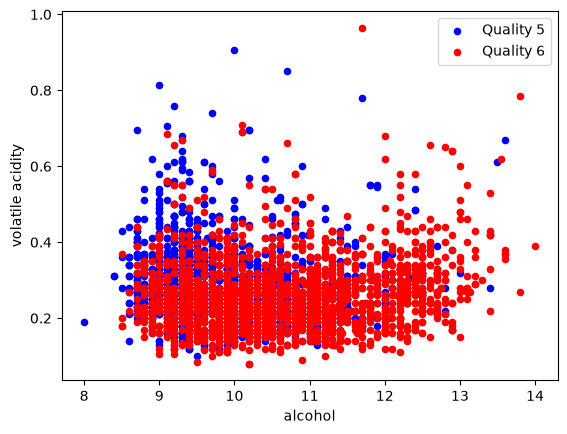

In [32]:
import matplotlib.pyplot as plt

ax = df[df['quality'] == 5].plot(
    kind='scatter',
    x='alcohol',
    y='volatile acidity',
    color='Blue',
    label='Quality 5'
)

df[df['quality'] == 6].plot(
    kind='scatter',
    x='alcohol',
    y='volatile acidity',
    color='Red',
    label='Quality 6',
    ax=ax
)

plt.show()

# Exploring Data Types and Class Distribution

### This section examines the data types of each column and the distribution of wine quality scores.

### - **`df.dtypes`**: Displays the data type of each column.
### - **`value_counts()`**: Counts the number of occurrences of each quality score.

### This helps understand the dataset structure and identify the distribution of target classes before training the model.

In [45]:
df.dtypes 
print(df['quality'].value_counts())

quality
6    2198
5    1457
7     880
8     175
4     163
3      20
9       5
Name: count, dtype: int64


# Feature Selection and NumPy Conversion

### This section selects 11 physicochemical features from the dataset and converts them into a NumPy array.

### - **`feature_df`**: Selects the input features, excluding the target column (`quality`).
### - **`np.asarray()`**: Converts the selected DataFrame into a NumPy array.
### - **`X[0:5]`**: Displays the first 5 samples of the feature array.

In [34]:
feature_df = df[['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH','sulphates','alcohol']]	
X = np.asarray(feature_df)
X[0:5]

array([[7.000e+00, 2.700e-01, 3.600e-01, 2.070e+01, 4.500e-02, 4.500e+01,
        1.700e+02, 1.001e+00, 3.000e+00, 4.500e-01, 8.800e+00],
       [6.300e+00, 3.000e-01, 3.400e-01, 1.600e+00, 4.900e-02, 1.400e+01,
        1.320e+02, 9.940e-01, 3.300e+00, 4.900e-01, 9.500e+00],
       [8.100e+00, 2.800e-01, 4.000e-01, 6.900e+00, 5.000e-02, 3.000e+01,
        9.700e+01, 9.951e-01, 3.260e+00, 4.400e-01, 1.010e+01],
       [7.200e+00, 2.300e-01, 3.200e-01, 8.500e+00, 5.800e-02, 4.700e+01,
        1.860e+02, 9.956e-01, 3.190e+00, 4.000e-01, 9.900e+00],
       [7.200e+00, 2.300e-01, 3.200e-01, 8.500e+00, 5.800e-02, 4.700e+01,
        1.860e+02, 9.956e-01, 3.190e+00, 4.000e-01, 9.900e+00]])

# Feature Selection and NumPy Conversion

### This section selects 11 physicochemical features from the dataset and converts them into a NumPy array.

### - **`feature_df`**: Selects the input features, excluding the target column (`quality`).
### - **`np.asarray()`**: Converts the selected DataFrame into a NumPy array.
### - **`X[0:5]`**: Displays the first 5 samples of the feature array.

In [35]:
y = np.asarray(df['quality'])
y[0:5]

array([6, 6, 6, 6, 6])

# Splitting the Dataset

### This section splits the dataset into training and testing sets using `train_test_split()`.

### - **`X_train` and `y_train`**: Used to train the machine learning model.
### - **`X_test` and `y_test`**: Used to evaluate the model's performance.
### - **`test_size=0.2`**: Allocates 20% of the data for testing and 80% for training.
### - **`random_state=4`**: Ensures reproducible data splitting.
### - **`.shape`**: Displays the dimensions of the training and testing datasets.

In [36]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2 , random_state=4)
print('train set:',X_train.shape , y_train.shape)
print('test set:',X_test.shape , y_test.shape)

train set: (3918, 11) (3918,)
test set: (980, 11) (980,)


# Train-Test Split

### This section divides the dataset into training and testing sets.

### - **`train_test_split()`**: Splits the features (`X`) and target (`y`).
### - **`test_size=0.2`**: Uses 80% of the data for training and 20% for testing.
### - **`random_state=4`**: Ensures reproducible results.
### - **`.shape`**: Displays the dimensions of each dataset.

### The training set is used to build the SVM model, while the testing set is used to evaluate its performance.

In [37]:
from sklearn import svm
clf = svm.SVC(kernel='rbf')
clf.fit(X_train,y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


# Model Prediction

### This section uses the trained SVM model to predict wine quality.

### - **`clf.predict(X_test)`**: Generates predictions for the test dataset and stores them in `yhat`.
### - **`X[0:5]`**: Displays the first 5 samples of the original feature dataset.

### The predicted values can be compared with the actual target values to evaluate model performance.

In [38]:
yhat = clf.predict(X_test)
X[0:5]

array([[7.000e+00, 2.700e-01, 3.600e-01, 2.070e+01, 4.500e-02, 4.500e+01,
        1.700e+02, 1.001e+00, 3.000e+00, 4.500e-01, 8.800e+00],
       [6.300e+00, 3.000e-01, 3.400e-01, 1.600e+00, 4.900e-02, 1.400e+01,
        1.320e+02, 9.940e-01, 3.300e+00, 4.900e-01, 9.500e+00],
       [8.100e+00, 2.800e-01, 4.000e-01, 6.900e+00, 5.000e-02, 3.000e+01,
        9.700e+01, 9.951e-01, 3.260e+00, 4.400e-01, 1.010e+01],
       [7.200e+00, 2.300e-01, 3.200e-01, 8.500e+00, 5.800e-02, 4.700e+01,
        1.860e+02, 9.956e-01, 3.190e+00, 4.000e-01, 9.900e+00],
       [7.200e+00, 2.300e-01, 3.200e-01, 8.500e+00, 5.800e-02, 4.700e+01,
        1.860e+02, 9.956e-01, 3.190e+00, 4.000e-01, 9.900e+00]])

# Importing Evaluation Metrics

### This section imports the tools needed to evaluate the SVM classification model.

### - **`classification_report`**: Provides precision, recall, F1-score, and support for each class.
### - **`confusion_matrix`**: Creates a matrix showing correct and incorrect predictions.
### - **`itertools`**: Provides tools for iterating through matrix indices when visualizing the confusion matrix.

In [39]:
from sklearn.metrics import classification_report, confusion_matrix
import itertools

# Creating a Confusion Matrix Function

### This section defines a custom function to calculate and visualize the confusion matrix.

### - **`cm`**: Contains the confusion matrix values.
### - **`classes`**: Defines the class labels.
### - **`normalize`**: Converts values into proportions when set to `True`.
### - **`plt.imshow()`**: Displays the confusion matrix as a heatmap.
### - **`plt.colorbar()`**: Adds a color scale.
### - **`itertools.product()`**: Iterates through matrix positions to display numerical values.
### - **`plt.text()`**: Displays values inside each cell.
### - **`True label`**: Represents actual classes.
### - **`Predicted label`**: Represents predicted classes.
### This function helps visualize the correct and incorrect predictions made by the SVM model.

In [40]:
import numpy as np
import matplotlib.pyplot as plt
import itertools

def plot_confusion_matrix(
    cm,
    classes,
    normalize=False,
    title='Confusion matrix',
    cmap=plt.cm.Blues
):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting normalize=True.
    """

    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

    print(cm)

    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()

    tick_marks = np.arange(len(classes))

    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    fmt = '.2f' if normalize else 'd'
    thresh = cm.max() / 2.

    for i, j in itertools.product(
        range(cm.shape[0]), range(cm.shape[1])
    ):
        plt.text(
            j, i, format(cm[i, j], fmt),
            horizontalalignment='center',
            color='white' if cm[i, j] > thresh else 'black'
        )

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

# Confusion Matrix Visualization

### This section generates and visualizes the confusion matrix to evaluate the SVM model's classification performance.

### - **`clf.predict(X_test)`**: Predicts wine quality using the trained model.
### - **`np.unique(y_test)`**: Identifies all unique quality classes.
### - **`confusion_matrix()`**: Compares actual and predicted labels.
### - **`plt.figure()`**: Sets the figure size.
### - **`plot_confusion_matrix()`**: Displays the confusion matrix with class labels.
### - **`plt.show()`**: Displays the final visualization.

### The confusion matrix helps identify correct predictions and classification errors across all wine quality classes.

Confusion matrix, without normalization
[[  0   0   1   3   0   0   0]
 [  0   0   3  29   0   0   0]
 [  0   0  33 251   0   0   0]
 [  0   0  33 413   0   0   0]
 [  0   0   3 168   0   0   0]
 [  0   0   2  40   0   0   0]
 [  0   0   0   1   0   0   0]]


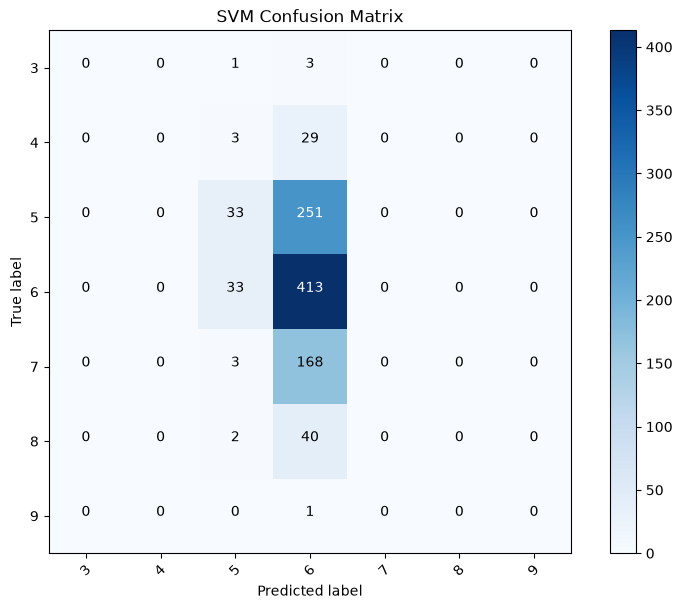

In [41]:
from sklearn.metrics import confusion_matrix

yhat = clf.predict(X_test)

classes = np.unique(y_test)

cm = confusion_matrix(y_test, yhat, labels=classes)

plt.figure(figsize=(8, 6))

plot_confusion_matrix(
    cm=cm,
    classes=classes,
    normalize=False,
    title='SVM Confusion Matrix'
)

plt.show()

### Model Evaluation

### This section evaluates the SVM model using a Confusion Matrix and Classification Report.

### - **`classes`**: Defines all wine quality classes (3 to 9).
### - **`confusion_matrix()`**: Compares actual and predicted wine quality labels.
### - **`np.set_printoptions()`**: Controls the numerical display precision.
### - **`classification_report()`**: Calculates evaluation metrics for each class:
### - **Precision:** How many predicted samples were correct.
### - **Recall:** How many actual samples were correctly identified.
### - **F1-score:** Harmonic mean of precision and recall.- **Support:** Number of actual samples in each class.
- **`zero_division=0`**: Returns zero when a metric cannot be calculated due to zero predictions.

This evaluation helps measure how accurately the SVM model classifies all wine quality categories.

In [47]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np
import matplotlib.pyplot as plt

# All wine quality classes
classes = [3, 4, 5, 6, 7, 8, 9]

# Compute confusion matrix
cnf_matrix = confusion_matrix(y_test, yhat, labels=classes)

np.set_printoptions(precision=2)

# Print classification report
print(classification_report(
    y_test,
    yhat,
    labels=classes,
    target_names=[
        'Quality 3',
        'Quality 4',
        'Quality 5',
        'Quality 6',
        'Quality 7',
        'Quality 8',
        'Quality 9'
    ],
    zero_division=0
))



              precision    recall  f1-score   support

   Quality 3       0.00      0.00      0.00         4
   Quality 4       0.00      0.00      0.00        32
   Quality 5       0.44      0.12      0.18       284
   Quality 6       0.46      0.93      0.61       446
   Quality 7       0.00      0.00      0.00       171
   Quality 8       0.00      0.00      0.00        42
   Quality 9       0.00      0.00      0.00         1

    accuracy                           0.46       980
   macro avg       0.13      0.15      0.11       980
weighted avg       0.34      0.46      0.33       980

